In [ ]:
#Seaborn, matplotlib, pandas, numpy. - Regular data analysis
#Bigdata analysis - Unstructured. New tools. ---> Convert it to a known strucutre. ---> vectors[group of numbers]

In [ ]:
#Pyspark. : Setup our data+data loading+exploration of big data.


In [ ]:
#Import necessary libraries.
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *

import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
spark = SparkSession.builder .appName("Restaurant reviews using big data").getOrCreate()

print("Version of spark", spark.version) #Spark settings are done.

Version of spark 4.0.3


In [ ]:
df=spark.read.csv("/content/Restaurant_Reviews.tsv", sep="\t", header=True, inferSchema=True)

In [ ]:
df.show(10)

+--------------------+-----+
|              Review|Liked|
+--------------------+-----+
|Wow... Loved this...|    1|
|  Crust is not good.|    0|
|Not tasty and the...|    0|
|Stopped by during...|    1|
|The selection on ...|    1|
|Now I am getting ...|    0|
|Honeslty it didn'...|    0|
|The potatoes were...|    0|
|The fries were gr...|    1|
|      A great touch.|    1|
+--------------------+-----+
only showing top 10 rows


In [ ]:
df=df.toDF("Review","Liked") #Rename columns

In [ ]:
df.show(10, truncate=False) #without cropping the display. wow. Wow WOW woW

+---------------------------------------------------------------------------------------------------------------+-----+
|Review                                                                                                         |Liked|
+---------------------------------------------------------------------------------------------------------------+-----+
|Wow... Loved this place.                                                                                       |1    |
|Crust is not good.                                                                                             |0    |
|Not tasty and the texture was just nasty.                                                                      |0    |
|Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.                        |1    |
|The selection on the menu was great and so were the prices.                                                    |1    |
|Now I am getting angry and I want my da

In [ ]:
print("Total number of reviews", df.count())

Total number of reviews 1000


In [ ]:
df.columns

['Review', 'Liked']

In [ ]:
df.printSchema()

root
 |-- Review: string (nullable = true)
 |-- Liked: integer (nullable = true)



In [ ]:
df.describe().show()

+-------+--------------------+------------------+
|summary|              Review|             Liked|
+-------+--------------------+------------------+
|  count|                1000|              1000|
|   mean|                NULL|               0.5|
| stddev|                NULL|0.5002501876563867|
|    min|!....THE OWNERS R...|                 0|
|    max|you can watch the...|                 1|
+-------+--------------------+------------------+



In [ ]:
df.select(count( when(col("Review").isNull(),True)).alias("Missing Reviews"),count(when(col("Liked").isNull(),True)).alias("Missing Labels")).show()

+---------------+--------------+
|Missing Reviews|Missing Labels|
+---------------+--------------+
|              0|             0|
+---------------+--------------+



In [ ]:
#dropna() - deleting null values.
df=df.dropna()

In [ ]:
#removing duplicates
print("Count before removing dupllicates", df.count())
df=df.dropDuplicates()
print("Count after removing duplicates", df.count())

Count before removing dupllicates 1000
Count after removing duplicates 996


In [ ]:
#What are the sentiments? Positve, negative, neutral review
#The headphones work well and worth the money- positive -2
#The headphones dont work well and it is a waste of money- negative

In [ ]:
#Lexicon based approach - list of words
#List of positive words, list of negative words

In [ ]:
#In customer review dataset 0-negative review, 1-positive review

In [ ]:
sentiment_count = (
    df.groupBy("Liked")
      .count()
      .orderBy("Liked")
)
sentiment_count.show()

+-----+-----+
|Liked|count|
+-----+-----+
|    0|  497|
|    1|  499|
+-----+-----+



In [ ]:
sentiment_pd=sentiment_count.toPandas()

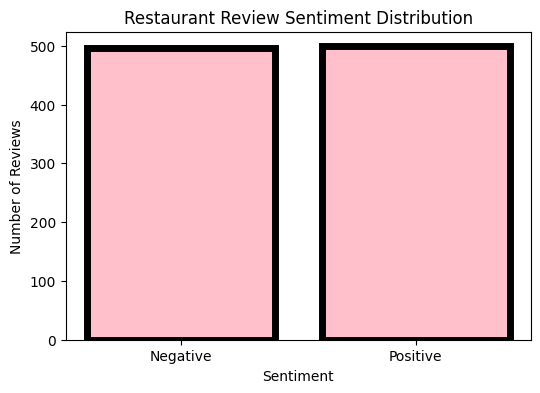

In [ ]:
plt.figure(figsize=(6,4))
plt.bar(sentiment_pd["Liked"].astype(str),sentiment_pd["count"], color='pink', edgecolor="black", linewidth=5)

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.title("Restaurant Review Sentiment Distribution")
plt.xticks([0,1], ["Negative","Positive"])
plt.savefig("sentiment distibution.jpg")
plt.show()

In [ ]:
from pyspark.sql.functions import lower, regexp_replace, trim, length, split

# Convert to lowercase
df = df.withColumn(
    "Clean_Review",
    lower(col("Review"))
)
# Remove punctuation and special characters
df = df.withColumn(
    "Clean_Review",
    regexp_replace(col("Clean_Review"), "[^a-zA-Z ]", ""))
# Remove extra spaces
df = df.withColumn(
    "Clean_Review",
    trim(regexp_replace(col("Clean_Review"), "\\s+", " "))
)

df.select("Review","Clean_Review").show(10, truncate=False)

+---------------------------------------------------------------------------------------+--------------------------------------------------------------------------------------+
|Review                                                                                 |Clean_Review                                                                          |
+---------------------------------------------------------------------------------------+--------------------------------------------------------------------------------------+
|Nice blanket of moz over top but i feel like this was done to cover up the subpar food.|nice blanket of moz over top but i feel like this was done to cover up the subpar food|
|We literally sat there for 20 minutes with no one asking to take our order.            |we literally sat there for minutes with no one asking to take our order               |
|Soggy and not good.                                                                    |soggy and not good        

In [ ]:
# Review length
df = df.withColumn(
    "Review_Length",
    length(col("Clean_Review"))
)

In [ ]:
# Word count
df = df.withColumn(
    "Word_Count",
    size(split(col("Clean_Review"), " "))
)

In [ ]:
df.show(10)

+--------------------+-----+--------------------+-------------+----------+
|              Review|Liked|        Clean_Review|Review_Length|Word_Count|
+--------------------+-----+--------------------+-------------+----------+
|Nice blanket of m...|    1|nice blanket of m...|           86|        19|
|We literally sat ...|    0|we literally sat ...|           71|        14|
| Soggy and not good.|    0|  soggy and not good|           18|         4|
|It's worth drivin...|    1|its worth driving...|           32|         6|
|After waiting an ...|    0|after waiting an ...|           73|        15|
|         DELICIOUS!!|    1|           delicious|            9|         1|
|This is the place...|    1|this is the place...|           58|        13|
|Our server was su...|    1|our server was su...|           54|        11|
|This is a good jo...|    1|this is a good joint|           20|         5|
|What a great doub...|    1|what a great doub...|           32|         5|
+--------------------+---

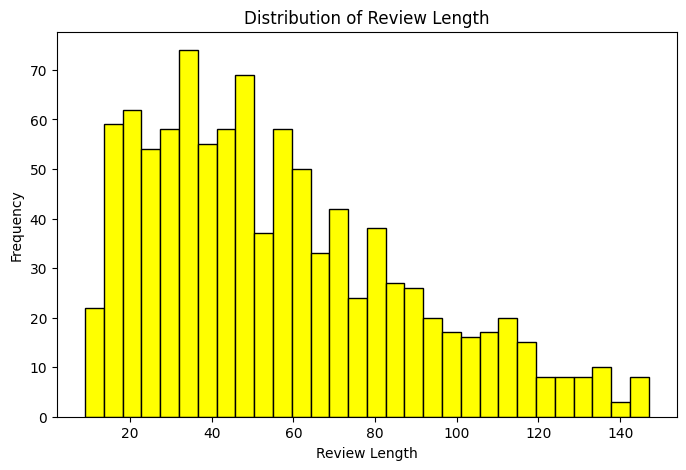

In [ ]:
# Review length visualization
length_pd = df.select("Review_Length").toPandas()

plt.figure(figsize=(8,5))
plt.hist(length_pd["Review_Length"], bins=30, edgecolor="black", color="yellow")

plt.xlabel("Review Length")
plt.ylabel("Frequency")
plt.title("Distribution of Review Length")

plt.show()

In [ ]:
#The food was good. - string
#Changing into tokens
#[The, food, was, good]-- tokens
#What can you do?---- [what, can , you , do]

In [ ]:
from pyspark.ml.feature import Tokenizer, StopWordsRemover
tokenizer = Tokenizer(
    inputCol="Clean_Review",
    outputCol="Words"
)

df = tokenizer.transform(df)

df.show(10, truncate=False)

+---------------------------------------------------------------------------------------+-----+--------------------------------------------------------------------------------------+-------------+----------+----------------------------------------------------------------------------------------------------------+
|Review                                                                                 |Liked|Clean_Review                                                                          |Review_Length|Word_Count|Words                                                                                                     |
+---------------------------------------------------------------------------------------+-----+--------------------------------------------------------------------------------------+-------------+----------+----------------------------------------------------------------------------------------------------------+
|Nice blanket of moz over top but i feel like this was 

In [ ]:
#Stop words -- redundant grammatical words which does not contribute to analysis of sentiment(postive or negative or neutral)
stop_words=StopWordsRemover()
sw_content=stop_words.getStopWords()
print(sw_content)
print("Length", len(sw_content))

['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', 'her', 'hers', 'herself', 'it', 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', 'too', 'very', 's', 't', 'can', 'will', 'just', 'don', 'should', 'no

In [ ]:
# Remove stop words
stopword_remover = StopWordsRemover(
    inputCol="Words",
    outputCol="Filtered_Words"
)

df = stopword_remover.transform(df)



In [ ]:
df.select("Words","Filtered_Words").show(10, truncate=False)

+----------------------------------------------------------------------------------------------------------+----------------------------------------------------------------+
|Words                                                                                                     |Filtered_Words                                                  |
+----------------------------------------------------------------------------------------------------------+----------------------------------------------------------------+
|[nice, blanket, of, moz, over, top, but, i, feel, like, this, was, done, to, cover, up, the, subpar, food]|[nice, blanket, moz, top, feel, like, done, cover, subpar, food]|
|[we, literally, sat, there, for, minutes, with, no, one, asking, to, take, our, order]                    |[literally, sat, minutes, one, asking, take, order]             |
|[soggy, and, not, good]                                                                                   |[soggy, good]         

In [ ]:
df.show(10)

+--------------------+-----+--------------------+-------------+----------+--------------------+--------------------+--------------------+
|              Review|Liked|        Clean_Review|Review_Length|Word_Count|               Words|      Filtered_Words|Filtered_Word_Length|
+--------------------+-----+--------------------+-------------+----------+--------------------+--------------------+--------------------+
|Nice blanket of m...|    1|nice blanket of m...|           86|        19|[nice, blanket, o...|[nice, blanket, m...|                  10|
|We literally sat ...|    0|we literally sat ...|           71|        14|[we, literally, s...|[literally, sat, ...|                   7|
| Soggy and not good.|    0|  soggy and not good|           18|         4|[soggy, and, not,...|       [soggy, good]|                   2|
|It's worth drivin...|    1|its worth driving...|           32|         6|[its, worth, driv...|[worth, driving, ...|                   3|
|After waiting an ...|    0|after 

In [ ]:
df = df.withColumn(
    "Filtered_Word_Length",
    size(col("Filtered_Words"))
)

In [ ]:
df.show(10)

+--------------------+-----+--------------------+-------------+----------+--------------------+--------------------+--------------------+
|              Review|Liked|        Clean_Review|Review_Length|Word_Count|               Words|      Filtered_Words|Filtered_Word_Length|
+--------------------+-----+--------------------+-------------+----------+--------------------+--------------------+--------------------+
|Nice blanket of m...|    1|nice blanket of m...|           86|        19|[nice, blanket, o...|[nice, blanket, m...|                  10|
|We literally sat ...|    0|we literally sat ...|           71|        14|[we, literally, s...|[literally, sat, ...|                   7|
| Soggy and not good.|    0|  soggy and not good|           18|         4|[soggy, and, not,...|       [soggy, good]|                   2|
|It's worth drivin...|    1|its worth driving...|           32|         6|[its, worth, driv...|[worth, driving, ...|                   3|
|After waiting an ...|    0|after 